<a href="https://colab.research.google.com/github/Don6abo/Laboratorio-Pizzas-Java/blob/master/Copia_de_LAB_D6_FGD_2026II_Ticona_Corrales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LABORATORIO DIRIGIDO N.° 06 — AutoFlota Andina
**Fundamentos de Gestión de Datos | Semana 6 | 2026-II**

Limpieza de Auto MPG, SQLite, regresión lineal simple y múltiple, métricas, resúmenes estadísticos y diagnósticos. Ejecute todas las celdas en orden.

**Estudiante:** Choque Castro, Allem Isaías · **Sección:** C28R 1ero B-L · **Trabajo individual**

## A. Diagnóstico y limpieza

### Celda 1 — Preparación del entorno y carga de datos

In [ ]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
columnas = ["rendimiento_mpg", "cilindros", "cilindrada", "potencia", "peso",
 "aceleracion", "anio_modelo", "codigo_origen", "nombre_auto"]
crudo = pd.read_csv(url, sep=r"\s+", names=columnas, na_values="?")
conexion = sqlite3.connect(":memory:")
crudo.to_sql("autos_original", conexion, index=False)
autos = pd.read_sql_query("SELECT * FROM autos_original;", conexion)
autos["marca"] = autos["nombre_auto"].str.split().str[0]
print("Filas y columnas:", autos.shape)

Filas y columnas: (398, 10)


### Celda 2 — Valores faltantes, duplicados y tipos

In [ ]:
faltantes = autos.isna().sum()
print("Valores faltantes por columna (solo las que tienen):")
display(faltantes[faltantes > 0])
print("Filas duplicadas:", autos.duplicated().sum())
display(autos.dtypes)

Valores faltantes por columna (solo las que tienen):


,0
potencia,6


Filas duplicadas: 0


,0
rendimiento_mpg,float64
cilindros,int64
cilindrada,float64
potencia,float64
peso,float64
aceleracion,float64
anio_modelo,int64
codigo_origen,int64
nombre_auto,object
marca,object


**Preguntas del laboratorio**

**Pregunta 1.** ¿Qué problemas de calidad aparecen en la celda 2: faltantes, duplicados y tipos de dato?

**Respuesta:** En la segunda celda se identifican 6 registros ausentes localizados exclusivamente en la variable potencia, mientras que no se registraron filas duplicadas. Respecto a la tipología de datos, los atributos numéricos continuos (rendimiento, cilindrada, potencia, peso y aceleración) están definidos como float64. Por su parte, cilindros, anio_modelo y codigo_origen corresponden a int64; no obstante, codigo_origen representa una variable categórica (con valores 1, 2 y 3) y no una magnitud numérica. Finalmente, nombre_auto y marca se clasifican como datos de tipo texto (object)..

### Celda 3 — Inconsistencias en marcas

In [ ]:
variantes = ["vw", "vokswagen", "volkswagen", "chevy", "chevroelt", "chevrolet",
 "maxda", "mazda", "toyouta", "toyota", "mercedes", "mercedes-benz"]
display(autos[autos["marca"].isin(variantes)]["marca"].value_counts().sort_index())
print("Marcas distintas antes de corregir:", autos["marca"].nunique())

,count
marca,
chevroelt,1
chevrolet,43
chevy,3
maxda,2
mazda,10
mercedes,1
mercedes-benz,2
toyota,25
toyouta,1


Marcas distintas antes de corregir: 37


**Preguntas del laboratorio**

**Pregunta 2.** ¿Qué inconsistencia muestra la celda 3 en la columna marca y por qué afectaría a un groupby?

**Respuesta:** En la celda 3 se evidencia inconsistencia en el registro de los nombres de las marcas, encontrándose variantes como vw (6), vokswagen (1) y volkswagen (15); chevy (3), chevroelt (1) y chevrolet (43); maxda (2) y mazda (10); toyouta (1) y toyota (25); así como mercedes (1) y mercedes-benz (2). Esto genera un total de 37 marcas diferentes previas a la limpieza de datos. Si se aplicara una agrupación mediante groupby sin corregir estas duplicidades, la función procesaría cada discrepancia como una entidad independiente, lo que alteraría los conteos y sesgaría los promedios por marca.

### Celda 4 — Imputación de potencia

In [ ]:
mediana = autos["potencia"].median()
promedio = autos["potencia"].mean()
print("Mediana de potencia:", mediana, "| promedio:", round(promedio, 2))
autos["potencia"] = autos["potencia"].fillna(mediana)
print("Faltantes en potencia después de imputar:", autos["potencia"].isna().sum())

Mediana de potencia: 93.5 | promedio: 104.47
Faltantes en potencia después de imputar: 0


**Preguntas del laboratorio**

**Pregunta 3.** ¿Por qué se imputa potencia con la mediana y no con el promedio? ¿Qué otra opción existía?

**Respuesta:** Se opta por imputar mediante la mediana (93.5) en lugar del promedio (104.47) debido a la resistencia de la mediana frente a los valores atípicos de potencia elevada; el promedio, al ser sensible a estas cifras extremas, habría sobreestimado los 6 registros faltantes. Entre las alternativas consideradas figuraban el descarte de las 6 filas incompletas (enfoque contrastado en el Reto 3) o la imputación agrupada, calculando por ejemplo la mediana según el número de cilindros del vehículo.

### Celda 5 — Origen, año y marcas

In [ ]:
autos["origen"] = autos["codigo_origen"].map({1: "USA", 2: "Europa", 3: "Japón"})
autos["anio"] = 1900 + autos["anio_modelo"]
correcciones = {"vw": "volkswagen", "vokswagen": "volkswagen", "chevy": "chevrolet",
 "chevroelt": "chevrolet", "maxda": "mazda", "toyouta": "toyota",
 "mercedes": "mercedes-benz"}
autos["marca"] = autos["marca"].replace(correcciones)
print("Marcas distintas después de corregir:", autos["marca"].nunique())
display(autos[["nombre_auto", "marca", "origen", "anio"]].head())

Marcas distintas después de corregir: 30


,nombre_auto,marca,origen,anio
0,chevrolet chevelle malibu,chevrolet,USA,1970
1,buick skylark 320,buick,USA,1970
2,plymouth satellite,plymouth,USA,1970
3,amc rebel sst,amc,USA,1970
4,ford torino,ford,USA,1970


**Preguntas del laboratorio**

**Pregunta 4.** ¿Qué corrigen origen, anio y replace()? ¿Cuántas marcas distintas quedan?

**Respuesta:** La variable origen transforma las codificaciones numéricas (1, 2 y 3) en etiquetas descriptivas (USA, Europa y Japón), mientras que anio ajusta los valores de dos dígitos sumándoles 1900 para reflejar el año completo (por ejemplo, 70 se convierte en 1970). Asimismo, mediante replace() se estandarizan las inconsistencias en los nombres de las marcas (vw por volkswagen, chevy por chevrolet, maxda por mazda, toyouta por toyota y mercedes por mercedes-benz, entre otras). Tras esta corrección, el catálogo se reduce a 30 marcas únicas.

### Celda 6 — Valores atípicos con IQR

In [ ]:
q1 = autos["potencia"].quantile(0.25)
q3 = autos["potencia"].quantile(0.75)
iqr = q3 - q1
limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
print("Q1:", q1, "| Q3:", q3, "| IQR:", iqr)
print("Límites:", round(limite_inf, 1), "y", round(limite_sup, 1))
atipicos = autos[(autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)]
print("Autos atípicos en potencia:", len(atipicos))
display(atipicos[["nombre_auto", "potencia", "cilindros", "peso"]]
 .sort_values("potencia", ascending=False).head(5))

Q1: 76.0 | Q3: 125.0 | IQR: 49.0
Límites: 2.5 y 198.5
Autos atípicos en potencia: 11


,nombre_auto,potencia,cilindros,peso
116,pontiac grand prix,230.0,8,4278.0
13,buick estate wagon (sw),225.0,8,3086.0
8,pontiac catalina,225.0,8,4425.0
95,buick electra 225 custom,225.0,8,4951.0
6,chevrolet impala,220.0,8,4354.0


**Preguntas del laboratorio**

**Pregunta 5.** ¿Cuáles son los límites del IQR en potencia y cuántos autos los superan? ¿Por qué se conservan?

**Respuesta:**Con los valores de Q1 = 76, Q3 = 125 y un IQR de 49, se fijan los límites en el intervalo [2.5, 198.5]. Se identifican 11 vehículos por encima del umbral superior, alcanzando el pontiac grand prix los 230 hp y figurando otros registros en los 225 hp. Estos datos se mantienen en el análisis dado que representan observaciones reales (los 5 de mayor caballaje poseen motores de 8 cilindros) y no inconsistencias en la toma de datos, por lo que su remoción omitiría información valiosa sobre la muestra.

### Celda 7 — Boxplots y marca de atípicos

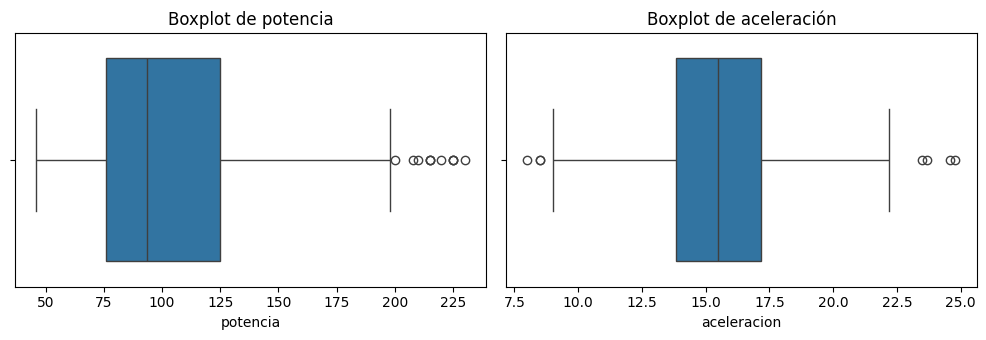

Autos marcados como atípicos (se conservan): 11


In [ ]:
autos["potencia_atipica"] = (autos["potencia"] < limite_inf) | (autos["potencia"] > limite_sup)
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.5))
sns.boxplot(x=autos["potencia"], ax=ejes[0])
ejes[0].set_title("Boxplot de potencia")
sns.boxplot(x=autos["aceleracion"], ax=ejes[1])
ejes[1].set_title("Boxplot de aceleración")
plt.tight_layout()
plt.show()
print("Autos marcados como atípicos (se conservan):", autos["potencia_atipica"].sum())

**Preguntas del laboratorio**

**Pregunta 6.** ¿Qué muestran los boxplots de potencia y de aceleración?

**Respuesta:** El diagrama de caja para la variable potencia presenta una mediana próxima a 93.5, con un rango intercuartílico que se extiende de 76 a 125 y valores atípicos concentrados exclusivamente en el extremo superior (entre 200 y 230 hp), lo que evidencia una distribución con sesgo positivo hacia valores elevados. En contraste, el diagrama de aceleración muestra una mediana cercana a 15.5 y una estructura más simétrica y compacta, registrando escasas observaciones extremas en ambos márgenes (alrededor de 8 y 8.5 a la izquierda, y entre 23.5 y 25 a la derecha).

### Celda 8 — Guardar datos limpios en SQLite

In [ ]:
autos.to_sql("autos_limpio", conexion, index=False, if_exists="replace")
consulta = """SELECT
 (SELECT COUNT(*) FROM autos_original) AS filas_original,
 (SELECT COUNT(*) FROM autos_limpio) AS filas_limpio,
 (SELECT COUNT(*) FROM autos_original WHERE potencia IS NULL) AS faltantes_original,
 (SELECT COUNT(*) FROM autos_limpio WHERE potencia IS NULL) AS faltantes_limpio;"""
display(pd.read_sql_query(consulta, conexion))

,filas_original,filas_limpio,faltantes_original,faltantes_limpio
0,398,398,6,0


**Preguntas del laboratorio**

**Pregunta 7.** ¿Qué cambió entre autos_original y autos_limpio? ¿Por qué no se sobrescribe la tabla original?

**Respuesta:** Ambos conjuntos de datos constan de 398 observaciones. En autos_original la variable potencia mantiene los 6 valores ausentes iniciales, mientras que en autos_limpio no existen registros nulos debido al proceso de imputación, figurando además estandarizados los atributos de origen, año y marca. Se evita la sobreescritura del dataset primario a fin de preservar la información cruda para propósitos de auditoría, garantizando la trazabilidad de las modificaciones y permitiendo explorar enfoques alternativos de procesamiento, tal como se aborda en el Reto 3.

## B. Regresión lineal

### Celda 9 — Separación entrenamiento y prueba

In [ ]:
y = autos["rendimiento_mpg"]
X_simple = autos[["peso"]]
X_train, X_test, y_train, y_test = train_test_split(
 X_simple, y, test_size=0.2, random_state=42)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Entrenamiento: (318, 1) | Prueba: (80, 1)


**Preguntas del laboratorio**

**Pregunta 8.** ¿Cuántos autos hay en entrenamiento y en prueba? ¿Para qué sirven la separación y random_state?

**Respuesta:** El conjunto de datos se divide en 318 vehículos para entrenamiento y 80 para prueba, representando una proporción de 80 % y 20 % respectivamente. Esta partición permite ajustar el modelo con un subconjunto de datos y posteriormente validar su desempeño frente a registros no observados, evaluando su capacidad de generalización. La inclusión de random_state = 42 asegura la reproducibilidad del proceso, garantizando que el muestreo aleatorio y las métricas resultantes se mantengan constantes en sucesivas ejecuciones.

### Celda 10 — Regresión simple con scikit-learn

Coeficiente de peso: -0.00781
Intercepto: 46.78
{'R2': 0.723, 'MAE': 3.12, 'MSE': 14.89, 'RMSE': np.float64(3.86)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        02:36:50   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
----------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,46.782063,3.145697e-154,44.972403,48.591724
peso,-0.007805,3.799579e-81,-0.008392,-0.007219


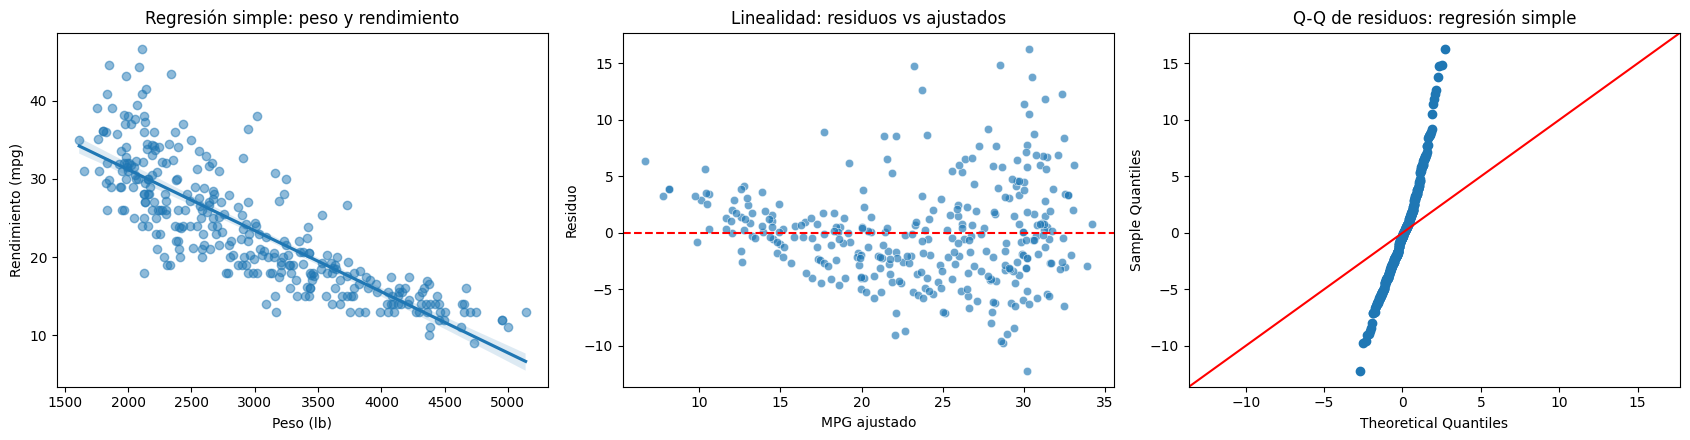

                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.684
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     685.5
Date:                Mon, 09 Nov 2026   Prob (F-statistic):           3.80e-81
Time:                        02:36:52   Log-Likelihood:                -925.80
No. Observations:                 318   AIC:                             1856.
Df Residuals:                     316   BIC:                             1863.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         46.7821      0.920     50.862      0.0

In [ ]:
def metricas(y_real, y_pred):
 mse = mean_squared_error(y_real, y_pred)
 return {"R2": round(r2_score(y_real, y_pred), 3),
 "MAE": round(mean_absolute_error(y_real, y_pred), 2),
 "MSE": round(mse, 2),
 "RMSE": round(np.sqrt(mse), 2)}

modelo_simple = LinearRegression()
modelo_simple.fit(X_train, y_train)
pred_simple = modelo_simple.predict(X_test)
print("Coeficiente de peso:", round(modelo_simple.coef_[0], 5))
print("Intercepto:", round(modelo_simple.intercept_, 2))
res_simple = metricas(y_test, pred_simple)
print(res_simple)

# Resumen estadístico, coeficientes y p-valores (regresión simple)
import statsmodels.api as sm
X_simple_sm = sm.add_constant(X_train)
modelo_simple_sm = sm.OLS(y_train, X_simple_sm).fit()
print(modelo_simple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_simple_sm.params,
 "p_valor": modelo_simple_sm.pvalues,
 "IC_95_inf": modelo_simple_sm.conf_int()[0],
 "IC_95_sup": modelo_simple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión simple)
ajustados_simple = modelo_simple_sm.fittedvalues
residuos_simple = modelo_simple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.regplot(x=X_train["peso"], y=y_train, ax=ejes[0], scatter_kws={"alpha": 0.5})
ejes[0].set(title="Regresión simple: peso y rendimiento", xlabel="Peso (lb)", ylabel="Rendimiento (mpg)")
sns.scatterplot(x=ajustados_simple, y=residuos_simple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_simple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión simple")
plt.tight_layout()
plt.show()

# Summary: coeficientes y p-valores de la regresión simple
import statsmodels.api as sm
modelo_simple_sm = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(modelo_simple_sm.summary())


**Preguntas del laboratorio**

**Pregunta 9.** Interprete el coeficiente de peso, el intercepto y las cuatro métricas del modelo simple.

**Respuesta:** El coeficiente de peso (−0.00781) indica que por cada libra adicional el rendimiento disminuye en aproximadamente 0.0078 mpg (o 0.78 mpg por cada 100 libras). El intercepto (46.78) representa el valor base de la recta yCarece de interpretación física directa al evaluar un peso nulo. El coeficiente R² (0.723) señala que la variable peso logra explicar cerca del 72 % de la variabilidad del rendimiento en el conjunto de prueba. Finalmente, en cuanto a los errores de predicción, se registra un MAE de 3.12 mpg, un MSE de 14.89 $\text{mpg}^2$ y un RMSE de 3.86 mpg como desviación típica de las estimaciones.

### Celda 11 — Regresión múltiple con scikit-learn

,variable,coeficiente
0,peso,-0.0070
1,potencia,0.0027
2,cilindrada,0.0026
3,aceleracion,0.0797
4,anio,0.8008


Intercepto: -1539.97
{'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}
                            OLS Regression Results                            
Dep. Variable:        rendimiento_mpg   R-squared:                       0.804
Model:                            OLS   Adj. R-squared:                  0.801
Method:                 Least Squares   F-statistic:                     255.8
Date:                Mon, 09 Nov 2026   Prob (F-statistic):          4.62e-108
Time:                        02:36:52   Log-Likelihood:                -850.20
No. Observations:                 318   AIC:                             1712.
Df Residuals:                     312   BIC:                             1735.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------

,coeficiente,p_valor,IC_95_inf,IC_95_sup
const,-1539.973203,2.340422e-29,-1782.300119,-1297.646287
peso,-0.007029,1.572087e-18,-0.008506,-0.005552
potencia,0.002657,8.646462e-01,-0.027988,0.033302
cilindrada,0.002625,6.714209e-01,-0.009540,0.014790
aceleracion,0.079661,4.831939e-01,-0.143612,0.302933
anio,0.800782,9.879430e-31,0.678449,0.923114


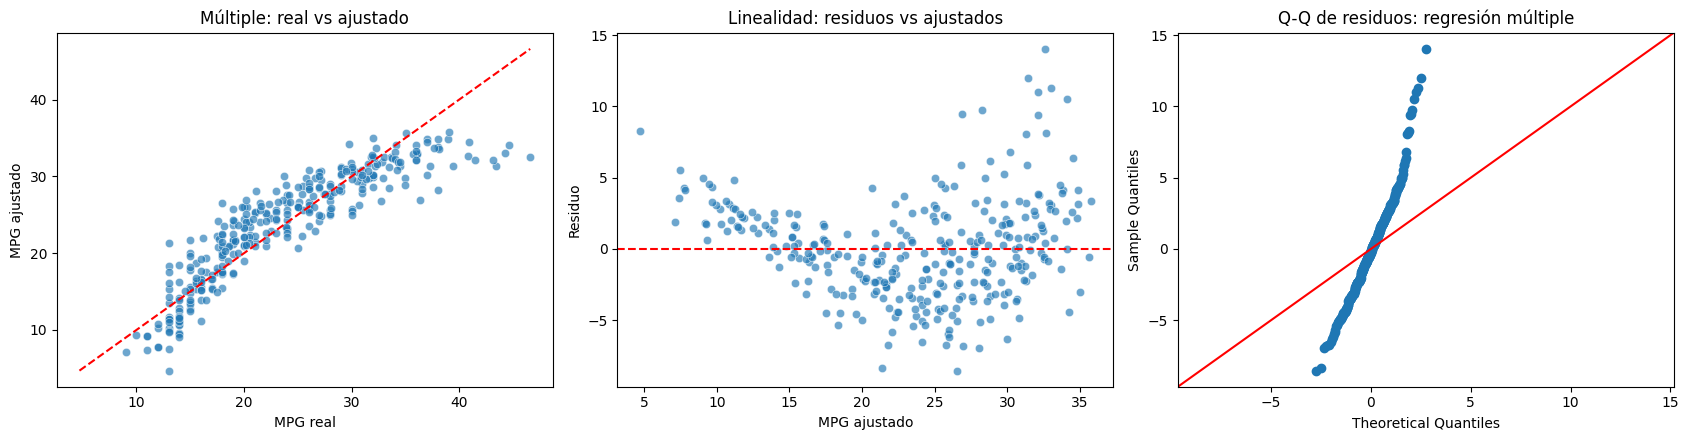

In [ ]:
variables = ["peso", "potencia", "cilindrada", "aceleracion", "anio"]
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
 autos[variables], y, test_size=0.2, random_state=42)
modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_multiple = modelo_multiple.predict(Xm_test)
display(pd.DataFrame({"variable": variables, "coeficiente": modelo_multiple.coef_.round(4)}))
print("Intercepto:", round(modelo_multiple.intercept_, 2))
res_multiple = metricas(ym_test, pred_multiple)
print(res_multiple)

# Resumen estadístico, coeficientes y p-valores (regresión múltiple)
Xm_const = sm.add_constant(Xm_train)
modelo_multiple_sm = sm.OLS(ym_train, Xm_const).fit()
print(modelo_multiple_sm.summary())
print("\nCoeficientes y p-valores (entrenamiento):")
display(pd.DataFrame({"coeficiente": modelo_multiple_sm.params,
 "p_valor": modelo_multiple_sm.pvalues,
 "IC_95_inf": modelo_multiple_sm.conf_int()[0],
 "IC_95_sup": modelo_multiple_sm.conf_int()[1]}))

# Gráficas de linealidad, residuos y Q-Q (regresión múltiple)
ajustados_multiple = modelo_multiple_sm.fittedvalues
residuos_multiple = modelo_multiple_sm.resid
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.5))
sns.scatterplot(x=ym_train, y=ajustados_multiple, ax=ejes[0], alpha=0.65)
limites = [min(ym_train.min(), ajustados_multiple.min()), max(ym_train.max(), ajustados_multiple.max())]
ejes[0].plot(limites, limites, "r--")
ejes[0].set(title="Múltiple: real vs ajustado", xlabel="MPG real", ylabel="MPG ajustado")
sns.scatterplot(x=ajustados_multiple, y=residuos_multiple, ax=ejes[1], alpha=0.65)
ejes[1].axhline(0, color="red", linestyle="--")
ejes[1].set(title="Linealidad: residuos vs ajustados", xlabel="MPG ajustado", ylabel="Residuo")
sm.qqplot(residuos_multiple, line="45", ax=ejes[2])
ejes[2].set_title("Q-Q de residuos: regresión múltiple")
plt.tight_layout()
plt.show()



**Preguntas del laboratorio**

**Pregunta 10.** Interprete los coeficientes del modelo múltiple. ¿Qué llama la atención en potencia y por qué?

**Respuesta:** El peso presenta un coeficiente de −0.0070, indicando que, manteniendo el resto de las variables constantes, cada libra adicional reduce el rendimiento en aproximadamente 0.007 mpg. Por su parte, el año de modelo muestra un coeficiente positivo (+0.8008), lo que equivale a un incremento cercano a 0.80 mpg por cada año más reciente. Las variables aceleración (+0.0797) y cilindrada (+0.0026) ejercen impactos marginales, mientras que el intercepto (−1539.97) carece de interpretación práctica al situarse en el año 0. Resulta atípico que la potencia reporte un coeficiente positivo (+0.0027) —cuando un mayor caballaje suele implicar mayor consumo— y un p-valor no significativo de 0.865; este fenómeno responde a la multicolinealidad con el peso y la cilindrada, entre las cuales el modelo distribuye el efecto. En contraste, el peso resulta estadísticamente muy significativo (p-valor = 1.6e-18).

### Celda 12 — Comparación de modelos y gráfica de prueba

,simple (peso),múltiple (5 variables)
R2,0.723,0.826
MAE,3.120,2.460
MSE,14.890,9.380
RMSE,3.860,3.060


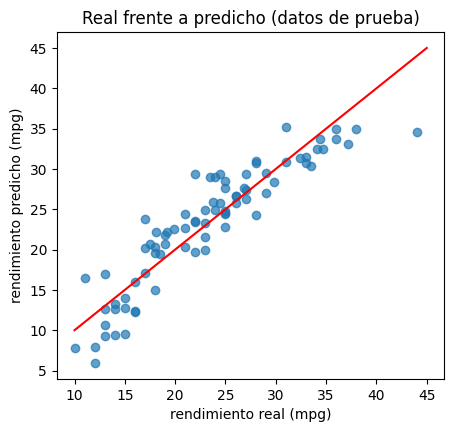

In [ ]:
comparacion = pd.DataFrame({"simple (peso)": res_simple,
 "múltiple (5 variables)": res_multiple})
display(comparacion)
plt.figure(figsize=(5, 4.5))
plt.scatter(ym_test, pred_multiple, alpha=0.7)
plt.plot([10, 45], [10, 45], color="red")
plt.xlabel("rendimiento real (mpg)")
plt.ylabel("rendimiento predicho (mpg)")
plt.title("Real frente a predicho (datos de prueba)")
plt.show()

**Preguntas del laboratorio**

**Pregunta 11.** Compare las métricas de los dos modelos. ¿Cuál es mejor y por qué se compara con los datos de prueba?

**Respuesta:** El modelo de regresión múltiple demuestra una capacidad predictiva superior al registrar mejores métricas de desempeño: R² de 0.826 frente a 0.723, MAE de 2.46 respecto a 3.12, MSE de 9.38 comparado con 14.89 y RMSE de 3.06 ante 3.86. La evaluación se realiza sobre el conjunto de prueba para contrastar la precisión en datos no observados durante la fase de ajuste, ya que la métrica en entrenamiento tiende a sobreestimar el rendimiento y no garantiza la facultad de generalización del algoritmo.

## Actividad 3 — Predicción para la flota

### Celda 13 — Candidatos de compra

In [ ]:
candidatos = pd.DataFrame({
 "candidato": ["A", "B", "C"],
 "peso": [2200, 3000, 4200],
 "potencia": [80, 110, 160],
 "cilindrada": [100, 200, 350],
 "aceleracion": [16, 15, 12],
 "anio": [1982, 1980, 1978]})
candidatos["rendimiento_predicho"] = modelo_multiple.predict(candidatos[variables]).round(1)
display(candidatos)

,candidato,peso,potencia,cilindrada,aceleracion,anio,rendimiento_predicho
0,A,2200,80,100,16,1982,33.5
1,B,3000,110,200,15,1980,26.5
2,C,4200,160,350,12,1978,16.7


**Preguntas del laboratorio**

**A.** ¿Qué candidato rinde más y cuál menos? ¿Qué características lo explican?

**Respuesta:** El vehículo A registra la mayor eficiencia energética (33.5 mpg), en contraste con el vehículo C, que presenta el menor rendimiento (16.7 mpg), situándose el vehículo B en una posición intermedia (26.5 mpg). Las características del candidato A corresponden a un menor peso (2200 lb), baja potencia (80 hp), reducida cilindrada (100) y un año de fabricación reciente (1982). Por el contrario, el candidato C destaca por ser el más pesado (4200 lb), con una potencia de 160 hp, motor de 350 de cilindrada y mayor antigüedad (1978). Dado que la masa del vehículo constituye el factor de mayor impacto negativo y el año de fabricación aporta positivamente al rendimiento, los resultados guardan plena coherencia con el comportamiento esperado.

**B.** Redacte una recomendación para AutoFlota Andina e indique los límites del modelo.

**Respuesta:** Se sugiere a AutoFlota Andina seleccionar prioritariamente el candidato A debido a su eficiencia (33.5 mpg) y desestimar la opción C, cuyo rendimiento resulta inferior en aproximadamente un 50 % (16.7 mpg). El candidato B representa un punto de equilibrio intermedio en caso de requerirse mayor capacidad operativa. Respecto a las limitaciones del modelo, cabe destacar que fue parametrizado con datos de vehículos fabricados entre 1970 y 1982, por lo que su valor es de carácter ilustrativo y carece de validez para evaluar flotas contemporáneas; presenta una margen de error estándar aproximado de ±3 mpg (RMSE = 3.06); y la estimación asociada al coeficiente de potencia carece de confiabilidad a causa de la multicolinealidad con el peso y la cilindrada.

## Retos de aplicación

### Celda 14 — Reto 1: variables por separado

In [ ]:
resultados = []
for variable in ["peso", "potencia", "cilindrada", "aceleracion", "anio"]:
 Xv_train, Xv_test, yv_train, yv_test = train_test_split(
 autos[[variable]], y, test_size=0.2, random_state=42)
 modelo = LinearRegression().fit(Xv_train, yv_train)
 resultados.append({"variable": variable,
 "coeficiente": round(modelo.coef_[0], 4),
 **metricas(yv_test, modelo.predict(Xv_test))})
tabla_simples = pd.DataFrame(resultados).sort_values("R2", ascending=False)
display(tabla_simples)

,variable,coeficiente,R2,MAE,MSE,RMSE
0,peso,-0.0078,0.723,3.12,14.89,3.86
2,cilindrada,-0.0617,0.663,3.39,18.10,4.25
1,potencia,-0.1640,0.640,3.51,19.37,4.40
4,anio,1.2914,0.287,5.36,38.32,6.19
3,aceleracion,1.1196,0.284,4.99,38.51,6.21


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué variable explica mejor el rendimiento por sí sola y cuál peor? Sustente con R² y RMSE e interprete el signo de los coeficientes.

**Respuesta:** **El peso destaca como el predictor individual con mayor capacidad explicativa sobre el rendimiento (R² = 0.723, RMSE = 3.86). En contraste, la aceleración reporta el menor desempeño (R² = 0.284, RMSE = 6.21), mostrando un resultado similar al del año de modelo (R² = 0.287). La dirección de los coeficientes concuerda con la teoría: peso (−0.0078), cilindrada (−0.0617) y potencia (−0.1640) exhiben relaciones negativas, confirmando que vehículos de mayor tamaño, masa y caballaje consumen más combustible. Por su parte, el año (+1.2914) y la aceleración (+1.1196) presentan signos positivos, dado que la tecnología reciente incrementa la eficiencia y un mayor tiempo de aceleración suele asociarse a automóviles de menor potencia y consumo moderado.

### Celda 15 — Reto 2: combinaciones de variables

In [ ]:
dummies = pd.get_dummies(autos["origen"], prefix="origen", drop_first=True).astype(int)
X_todo = pd.concat([autos[variables], dummies], axis=1)
combinaciones = {
 "peso + anio": ["peso", "anio"],
 "peso + potencia + anio": ["peso", "potencia", "anio"],
 "5 variables": variables,
 "5 variables + origen": list(X_todo.columns),
}
filas = []
for nombre, columnas_x in combinaciones.items():
 Xc_train, Xc_test, yc_train, yc_test = train_test_split(
 X_todo[columnas_x], y, test_size=0.2, random_state=42)
 modelo = LinearRegression().fit(Xc_train, yc_train)
 r = metricas(yc_test, modelo.predict(Xc_test))
 n, p = len(yc_test), len(columnas_x)
 r["R2_ajustado"] = round(1 - (1 - r["R2"]) * (n - 1) / (n - p - 1), 3)
 filas.append({"modelo": nombre, "variables": p, **r})
modelo_origen = modelo
print(dict(zip(X_todo.columns, modelo_origen.coef_.round(3))))
tabla_combos = pd.DataFrame(filas)
display(tabla_combos)

{'peso': np.float64(-0.007), 'potencia': np.float64(-0.014), 'cilindrada': np.float64(0.017), 'aceleracion': np.float64(0.07), 'anio': np.float64(0.827), 'origen_Japón': np.float64(-0.294), 'origen_USA': np.float64(-2.925)}


,modelo,variables,R2,MAE,MSE,RMSE,R2_ajustado
0,peso + anio,2,0.824,2.45,9.44,3.07,0.819
1,peso + potencia + anio,3,0.824,2.45,9.44,3.07,0.817
2,5 variables,5,0.826,2.46,9.38,3.06,0.814
3,5 variables + origen,7,0.843,2.29,8.47,2.91,0.828


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Qué combinación tiene el mayor R² ajustado? ¿Cuánto aporta agregar el origen y cuál es su categoría de referencia?

**Respuesta:** El modelo con mayor $R^2$ ajustado corresponde a la combinación de 5 variables más origen (0.828), superando los valores de peso + año (0.819), peso + potencia + año (0.817) y las 5 variables sin origen (0.814). La inclusión de la variable origen incrementa el $R^2$ de 0.826 a 0.843 y reduce el RMSE de 3.06 a 2.91. Se establece como categoría de referencia a Europa, dado que get_dummies con el argumento drop_first=True omite la primera categoría por orden alfabético, manteniendo únicamente origen_Japón y origen_USA. Controlando las demás variables, un vehículo estadounidense presenta un rendimiento aproximado de 2.9 mpg inferior respecto a uno europeo (coeficiente de −2.925), mientras que uno japonés muestra una diferencia marginal (−0.294).

### Celda 16 — Reto 3: imputar o eliminar

In [ ]:
original = pd.read_sql_query(
 "SELECT * FROM autos_original WHERE potencia IS NOT NULL;", conexion)
original["anio"] = 1900 + original["anio_modelo"]
Xe_train, Xe_test, ye_train, ye_test = train_test_split(
 original[variables], original["rendimiento_mpg"], test_size=0.2, random_state=42)
modelo_sin = LinearRegression().fit(Xe_train, ye_train)
print("Filas usadas:", len(original), "frente a", len(autos))
print("Eliminando faltantes:", metricas(ye_test, modelo_sin.predict(Xe_test)))
print("Imputando mediana: ", res_multiple)

Filas usadas: 392 frente a 398
Eliminando faltantes: {'R2': 0.793, 'MAE': 2.51, 'MSE': 10.58, 'RMSE': np.float64(3.25)}
Imputando mediana:  {'R2': 0.826, 'MAE': 2.46, 'MSE': 9.38, 'RMSE': np.float64(3.06)}


**Preguntas del laboratorio**

**Pregunta de cierre.** ¿Cuántos autos usa cada opción y cómo cambian las métricas? ¿Por qué la comparación debe hacerse con cuidado?

**Respuesta:** El descarte de registros incompletos reduce la muestra a 392 observaciones, obteniendo un $R^2$ de 0.793 y un RMSE de 3.25; por su parte, la imputación mediante la mediana mantiene los 398 registros, alcanzando un $R^2$ de 0.826 y un RMSE de 3.06. Aunque los resultados sugieren a primera vista una ventaja para la imputación, la comparación directa exige reserva: al variar el volumen del conjunto de datos se altera la partición entre entrenamiento y prueba, lo que implica que ambos modelos no se evalúan sobre la misma muestra. Adicionalmente, la imputación introduce datos sintéticos que no reflejan mediciones reales, de modo que las discrepancias observadas en el desempeño pueden atribuirse al sesgo en la selección de la muestra de prueba y no exclusivamente a la estrategia de limpieza empleada.

### Conclusiones

Tres conclusiones técnicas y de negocio de este laboratorio.

1. Tratamiento de datos: Se imputaron 6 nulos de potencia con la mediana (93.5), se unificaron 37 marcas erróneas en 30 correctas y se mantuvieron 11 atípicos reales de alta potencia, resguardando la tabla original de forma independiente.
2. Desempeño predictivo: Aunque el peso por sí solo justifica gran parte del rendimiento ($R^2 = 0.723$), la regresión múltiple incrementa la precisión a $R^2 = 0.826$ ($\text{RMSE} = 3.06$), subiendo a $0.843$ al sumar el origen. La potencia perdió confiabilidad individual debido a la multicolinealidad.
3. Decisión estratégica: Para AutoFlota Andina se sugiere adquirir el candidato A (33.5 mpg) en lugar del C (16.7 mpg), favoreciendo unidades ligeras y recientes. Se aclara que el modelo es de carácter referencial por basarse en vehículos de 1970 a 1982 y contar con un error promedio de $\pm 3\text{ mpg}$.